# NGÀY 5 – NGÀY 8: 3 SINGLE-MODAL BASELINES, MULTI-MODAL FUSION (2880-D), TUNING, 3-SEED MEAN±STD & ABLATION STUDY (43,982 MẪU - 4 LỚP)


In [12]:
# ── Cell 1: Tích hợp evaluate.py chuẩn của Hà (H13) ──────────────────────
evaluate_code = r'''import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

def evaluate_predictions(y_true, y_pred, class_names, model_name="Model", save_dir="/kaggle/working/results"):
    os.makedirs(save_dir, exist_ok=True)
    acc = accuracy_score(y_true, y_pred)
    macro_p = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_r = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

    print(f"=== KẾT QUẢ ĐÁNH GIÁ: {model_name} ===")
    print(f"Accuracy        : {acc:.4f}")
    print(f"Macro Precision : {macro_p:.4f}")
    print(f"Macro Recall    : {macro_r:.4f}")
    print(f"Macro F1-Score  : {macro_f1:.4f}")
    print("\n--- Báo cáo phân loại chi tiết ---")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}', fontsize=13, fontweight='bold')
    plt.ylabel('Thực tế (True)', fontsize=11)
    plt.xlabel('Dự đoán (Predicted)', fontsize=11)
    plt.tight_layout()
    img_path = os.path.join(save_dir, f"confusion_matrix_{model_name}.png")
    plt.savefig(img_path, dpi=200)
    plt.show()
    plt.close()
    print(f"Đã lưu biểu đồ Confusion Matrix tại: {img_path}\n")

    return {"accuracy": acc, "macro_precision": macro_p, "macro_recall": macro_r, "macro_f1": macro_f1}
'''
with open('/kaggle/working/evaluate.py', 'w', encoding='utf-8') as f:
    f.write(evaluate_code)

from evaluate import evaluate_predictions as evaluate_model
print("✅ Đã khởi tạo /kaggle/working/evaluate.py thành công!")


✅ Đã khởi tạo /kaggle/working/evaluate.py thành công!


## Cell 2: Load Features `.pt` + `clean_v0.csv` (43,982 mẫu) & Tiền xử lý Tabular theo Data Contract


In [13]:
import os, glob, json, random, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

# Tìm file clean_v0.csv, label_map.json và các file .pt (trong /kaggle/working hoặc /kaggle/input)
CSV_PATH   = glob.glob('/kaggle/input/**/clean_v0*.csv', recursive=True)[0]
LABEL_PATH = glob.glob('/kaggle/input/**/label_map*.json', recursive=True)[0]

df = pd.read_csv(CSV_PATH)
with open(LABEL_PATH, 'r', encoding='utf-8') as f:
    label_map = json.load(f)

CLASS_NAMES = [k for k, v in sorted(label_map.items(), key=lambda x: x[1])]
NUM_CLASSES = len(CLASS_NAMES)
print(f"Tổng mẫu: {len(df)} | Số lớp: {NUM_CLASSES} -> {CLASS_NAMES}")

def find_pt(filename):
    w_path = f'/kaggle/working/{filename}'
    if os.path.exists(w_path):
        return w_path
    matches = glob.glob(f'/kaggle/input/**/{filename}', recursive=True)
    assert len(matches) > 0, f"Không tìm thấy {filename}!"
    return matches[0]

# Tiền xử lý Tabular chuẩn Data Contract (gender, masterCategory, subCategory, baseColour, season, year)
# Lưu ý: KHÔNG đưa cột articleType vào Tabular vì articleType chứa tên nhãn ("Casual Shoes", "Formal Shoes", "Sports Shoes") gây Data Leakage
TAB_CAT_COLS = ['gender', 'masterCategory', 'subCategory', 'baseColour', 'season']
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

def build_tabular_features(df_sub, is_train=False):
    yr = pd.to_numeric(df_sub['year'], errors='coerce').fillna(2012.0).values.reshape(-1, 1)
    cat_df = df_sub[TAB_CAT_COLS].fillna('Unknown').astype(str)
    if is_train:
        yr_s = scaler.fit_transform(yr)
        cat_ohe = ohe.fit_transform(cat_df)
    else:
        yr_s = scaler.transform(yr)
        cat_ohe = ohe.transform(cat_df)
    return torch.tensor(np.hstack([yr_s, cat_ohe]), dtype=torch.float32)

data_splits = {}
for s in ['train', 'val', 'test']:
    df_s = df[df['split'] == s].reset_index(drop=True)
    img_d = torch.load(find_pt(f'image_feats_{s}.pt'), map_location='cpu')
    txt_d = torch.load(find_pt(f'text_feats_{s}.pt'), map_location='cpu')

    csv_ids = torch.tensor(df_s['id'].astype(int).values, dtype=torch.long)
    assert (img_d['ids'] == csv_ids).all() and (txt_d['ids'] == csv_ids).all(), f"Lệch ID ở tập {s}!"

    tab_t = build_tabular_features(df_s, is_train=(s == 'train'))
    y_t   = torch.tensor(df_s['label_idx'].astype(int).values, dtype=torch.long)

    data_splits[s] = {
        'img': img_d['feats'].float(),
        'txt': txt_d['feats'].float(),
        'tab': tab_t,
        'y':   y_t
    }
    print(f"✅ [{s:5s}] img={tuple(data_splits[s]['img'].shape)} | txt={tuple(data_splits[s]['txt'].shape)} | tab={tuple(tab_t.shape)} | y={tuple(y_t.shape)}")

TAB_IN_DIM = data_splits['train']['tab'].shape[1]

# Lưu bộ tiền xử lý Tabular cho Web Demo (Ngày 10)
with open('/kaggle/working/tabular_preprocessor.pkl', 'wb') as f:
    pickle.dump({'ohe': ohe, 'scaler': scaler, 'tab_cat_cols': TAB_CAT_COLS, 'tab_in_dim': TAB_IN_DIM}, f)

# Tính Class Weights (Smoothed Square-Root) xử lý mất cân bằng lớp (H18)
y_tr_np = data_splits['train']['y'].numpy()
counts = np.bincount(y_tr_np, minlength=NUM_CLASSES)
raw_weights = len(y_tr_np) / (NUM_CLASSES * np.maximum(counts, 1))
class_weights = torch.tensor(np.sqrt(raw_weights), dtype=torch.float32, device=DEVICE)
print("⚖️ Class Counts (Train):", dict(zip(CLASS_NAMES, counts.tolist())))
print("⚖️ Smoothed Class Weights:", np.round(class_weights.cpu().numpy(), 4).tolist())


Device: cuda
Tổng mẫu: 43982 | Số lớp: 4 -> ['Casual', 'Ethnic', 'Formal', 'Sports']
✅ [train] img=(30787, 2048) | txt=(30787, 768) | tab=(30787, 107) | y=(30787,)
✅ [val  ] img=(6597, 2048) | txt=(6597, 768) | tab=(6597, 107) | y=(6597,)
✅ [test ] img=(6598, 2048) | txt=(6598, 768) | tab=(6598, 107) | y=(6598,)
⚖️ Class Counts (Train): {'Casual': 24083, 'Ethnic': 2246, 'Formal': 1641, 'Sports': 2817}
⚖️ Smoothed Class Weights: [0.5652999877929688, 1.851199984550476, 2.1656999588012695, 1.652999997138977]


## Cell 3 & Cell 4: Kiến trúc Mạng (Task T14) & Hàm Training Loop Chuẩn (Task T15)


In [14]:
# ── Cell 3: T14 - Kiến trúc Single-Modal Heads & Multi-Modal Fusion (2880-d) ──

class TabularEncoder(nn.Module):
    '''Mã hóa vector Tabular đầu vào -> 64-d chuẩn thiết kế Charter.'''
    def __init__(self, in_dim=TAB_IN_DIM, out_dim=64, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, out_dim),
            nn.LayerNorm(out_dim),
            nn.ReLU()
        )
    def forward(self, x):
        return self.net(x)

class TabularBaselineModel(nn.Module):
    '''Model 1: Tabular-Only (Input -> 64-d -> NUM_CLASSES).'''
    def __init__(self, in_dim=TAB_IN_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        self.encoder = TabularEncoder(in_dim, 64, dropout=0.2)
        self.head = nn.Linear(64, num_classes)
    def forward(self, img, txt, tab):
        return self.head(self.encoder(tab))

class ImageBaselineModel(nn.Module):
    '''Model 2: Image-Only (ResNet50 2048-d -> 256 -> NUM_CLASSES).'''
    def __init__(self, in_dim=2048, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Dropout(dropout),
            nn.Linear(in_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
    def forward(self, img, txt, tab):
        return self.net(img)

class TextBaselineHead(nn.Module):
    '''Model 3: Text-Only (DistilBERT 768-d -> 256 -> NUM_CLASSES).'''
    def __init__(self, in_dim=768, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Dropout(dropout),
            nn.Linear(in_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
    def forward(self, img, txt, tab=None):
        # Cho phép gọi trực tiếp model(txt) hoặc model(img, txt, tab)
        x = img if txt is None else txt
        return self.net(x)

class MultiModalFusionHead(nn.Module):
    '''
    Model 4: Multi-Modal Fusion chuẩn thiết kế:
    Image (2048-d) + Text (768-d) + Tabular (64-d) -> Concat (2880-d) -> 512 -> 256 -> NUM_CLASSES
    Kết hợp LayerNorm từng nhánh (Debug Checklist 10.5) giúp cân bằng miền giá trị giữa 3 phương thức.
    '''
    def __init__(self, img_dim=2048, txt_dim=768, tab_in_dim=TAB_IN_DIM, num_classes=NUM_CLASSES,
                 hidden_dims=(512, 256), dropout=0.35, use_img=True, use_txt=True, use_tab=True):
        super().__init__()
        self.use_img, self.use_txt, self.use_tab = use_img, use_txt, use_tab
        h1, h2 = hidden_dims

        self.img_norm = nn.Sequential(nn.LayerNorm(img_dim), nn.Dropout(dropout))
        self.txt_norm = nn.Sequential(nn.LayerNorm(txt_dim), nn.Dropout(dropout * 0.7))
        self.tab_enc  = TabularEncoder(tab_in_dim, 64, dropout=0.2)

        self.fusion_net = nn.Sequential(
            nn.Linear(img_dim + txt_dim + 64, h1),
            nn.BatchNorm1d(h1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.BatchNorm1d(h2),
            nn.ReLU(),
            nn.Dropout(max(0.1, dropout - 0.1)),
            nn.Linear(h2, num_classes)
        )

    def forward(self, img, txt, tab):
        f_img = self.img_norm(img) if self.use_img else torch.zeros_like(img)
        f_txt = self.txt_norm(txt) if self.use_txt else torch.zeros_like(txt)
        f_tab = self.tab_enc(tab)  if self.use_tab else torch.zeros(img.size(0), 64, device=img.device)

        fused_2880 = torch.cat([f_img, f_txt, f_tab], dim=1)   # (B, 2880)
        return self.fusion_net(fused_2880)

# Unit test forward/backward (T14)
_m = MultiModalFusionHead().to(DEVICE)
_out = _m(torch.randn(8, 2048, device=DEVICE), torch.randn(8, 768, device=DEVICE), torch.randn(8, TAB_IN_DIM, device=DEVICE))
assert _out.shape == (8, NUM_CLASSES)
print(f"✅ T14 Unit Test PASSED: Output shape = {tuple(_out.shape)} (Concat 2880 -> 512 -> 256 -> {NUM_CLASSES})")


✅ T14 Unit Test PASSED: Output shape = (8, 4) (Concat 2880 -> 512 -> 256 -> 4)


In [15]:
# ── Cell 4: T15 - Hàm Training Loop chuẩn (CrossEntropy + AdamW + Early Stopping) ──
def train_model(model, epochs=25, lr=5e-4, weight_decay=1e-2, label_smoothing=0.0,
                patience=6, save_path='/kaggle/working/best_model.pth', seed=42, verbose=True):
    seed_everything(seed)
    model = model.to(DEVICE)

    tr_d, va_d = data_splits['train'], data_splits['val']
    tr_loader = DataLoader(TensorDataset(tr_d['img'], tr_d['txt'], tr_d['tab'], tr_d['y']), batch_size=256, shuffle=True)
    va_loader = DataLoader(TensorDataset(va_d['img'], va_d['txt'], va_d['tab'], va_d['y']), batch_size=256, shuffle=False)

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=label_smoothing)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

    best_f1 = -1.0
    no_improve = 0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}

    for ep in range(1, epochs + 1):
        model.train()
        tr_loss = 0.0
        for img, txt, tab, y in tr_loader:
            img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(img, txt, tab)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * y.size(0)
        tr_loss /= len(tr_loader.dataset)

        model.eval()
        va_loss = 0.0
        preds, trues = [], []
        with torch.no_grad():
            for img, txt, tab, y in va_loader:
                img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
                logits = model(img, txt, tab)
                loss = criterion(logits, y)
                va_loss += loss.item() * y.size(0)
                preds.append(logits.argmax(dim=1).cpu().numpy())
                trues.append(y.cpu().numpy())

        va_loss /= len(va_loader.dataset)
        preds, trues = np.concatenate(preds), np.concatenate(trues)
        va_acc = accuracy_score(trues, preds)
        va_f1  = f1_score(trues, preds, average='macro', zero_division=0)

        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)
        scheduler.step(va_f1)

        if va_f1 > best_f1:
            best_f1 = va_f1
            no_improve = 0
            torch.save(model.state_dict(), save_path)
            if verbose:
                print(f"Epoch {ep:02d} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f} | Val Acc: {va_acc:.4f} | Val Macro-F1: {va_f1:.4f} ⭐ Best")
        else:
            no_improve += 1
            if no_improve >= patience:
                if verbose:
                    print(f"⏹ Early stopping tại Epoch {ep:02d} (Best Val Macro-F1 = {best_f1:.4f})")
                break

    model.load_state_dict(torch.load(save_path))
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for img, txt, tab, y in va_loader:
            img, txt, tab = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE)
            preds.append(model(img, txt, tab).argmax(dim=1).cpu().numpy())
            trues.append(y.numpy())
    return np.concatenate(trues), np.concatenate(preds), history

print("✅ Đã khởi tạo xong hàm train_model (T15)!")


✅ Đã khởi tạo xong hàm train_model (T15)!


## Cell 5 & Cell 6: Huấn luyện & Đánh giá 3 Single-Modal Baselines + Multi-Modal Fusion (Ngày 5, 6, 7 - Chốt Gate M2 & M3)



1️⃣ HUẤN LUYỆN MODEL 1: TABULAR-ONLY (MLP)
Epoch 01 | Train Loss: 0.8542 | Val Loss: 0.6498 | Val Acc: 0.7617 | Val Macro-F1: 0.5833 ⭐ Best
Epoch 02 | Train Loss: 0.6668 | Val Loss: 0.6157 | Val Acc: 0.7650 | Val Macro-F1: 0.5952 ⭐ Best
Epoch 03 | Train Loss: 0.6405 | Val Loss: 0.6019 | Val Acc: 0.7657 | Val Macro-F1: 0.6032 ⭐ Best
Epoch 05 | Train Loss: 0.6170 | Val Loss: 0.5866 | Val Acc: 0.7597 | Val Macro-F1: 0.6074 ⭐ Best
Epoch 07 | Train Loss: 0.6041 | Val Loss: 0.5848 | Val Acc: 0.7675 | Val Macro-F1: 0.6093 ⭐ Best
⏹ Early stopping tại Epoch 13 (Best Val Macro-F1 = 0.6093)
=== KẾT QUẢ ĐÁNH GIÁ: Model1_Tabular_Only_Val ===
Accuracy        : 0.7675
Macro Precision : 0.5622
Macro Recall    : 0.7037
Macro F1-Score  : 0.6093

--- Báo cáo phân loại chi tiết ---
              precision    recall  f1-score   support

      Casual       0.92      0.79      0.85      5160
      Ethnic       0.49      0.88      0.63       481
      Formal       0.33      0.57      0.42       352
      Spo

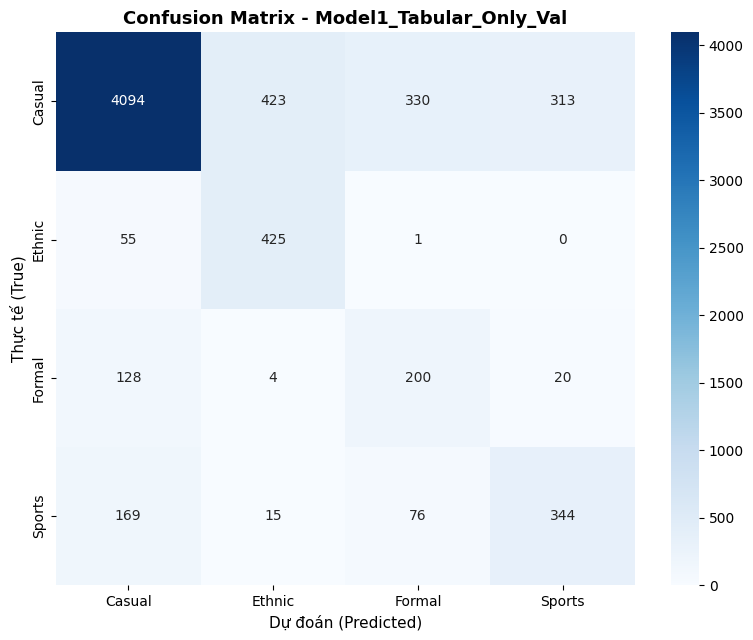

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model1_Tabular_Only_Val.png


2️⃣ HUẤN LUYỆN MODEL 2: IMAGE-ONLY (RESNET-50 2048-D)
Epoch 01 | Train Loss: 0.4951 | Val Loss: 0.3499 | Val Acc: 0.8681 | Val Macro-F1: 0.7816 ⭐ Best
Epoch 02 | Train Loss: 0.3532 | Val Loss: 0.3106 | Val Acc: 0.8863 | Val Macro-F1: 0.8088 ⭐ Best
Epoch 03 | Train Loss: 0.3176 | Val Loss: 0.2960 | Val Acc: 0.8901 | Val Macro-F1: 0.8189 ⭐ Best
Epoch 05 | Train Loss: 0.2826 | Val Loss: 0.2793 | Val Acc: 0.8963 | Val Macro-F1: 0.8300 ⭐ Best
Epoch 08 | Train Loss: 0.2510 | Val Loss: 0.2724 | Val Acc: 0.9047 | Val Macro-F1: 0.8394 ⭐ Best
Epoch 12 | Train Loss: 0.2118 | Val Loss: 0.2652 | Val Acc: 0.9084 | Val Macro-F1: 0.8434 ⭐ Best
Epoch 14 | Train Loss: 0.2005 | Val Loss: 0.2598 | Val Acc: 0.9087 | Val Macro-F1: 0.8491 ⭐ Best
Epoch 17 | Train Loss: 0.1906 | Val Loss: 0.2596 | Val Acc: 0.9115 | Val Macro-F1: 0.8504 ⭐ Best
Epoch 20 | Train Loss: 0.1744 | Val Loss: 0.2570 | Val Acc: 0.

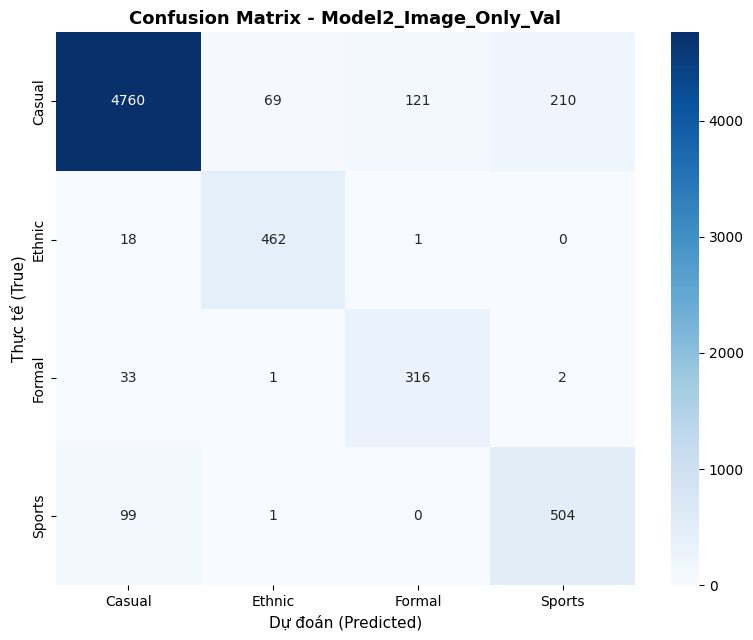

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model2_Image_Only_Val.png


3️⃣ HUẤN LUYỆN MODEL 3: TEXT-ONLY (DISTILBERT 768-D)
Epoch 01 | Train Loss: 0.6242 | Val Loss: 0.5084 | Val Acc: 0.7387 | Val Macro-F1: 0.6517 ⭐ Best
Epoch 02 | Train Loss: 0.4337 | Val Loss: 0.4004 | Val Acc: 0.8117 | Val Macro-F1: 0.7275 ⭐ Best
Epoch 03 | Train Loss: 0.3938 | Val Loss: 0.3784 | Val Acc: 0.8113 | Val Macro-F1: 0.7347 ⭐ Best
Epoch 04 | Train Loss: 0.3714 | Val Loss: 0.3600 | Val Acc: 0.8183 | Val Macro-F1: 0.7463 ⭐ Best
Epoch 05 | Train Loss: 0.3518 | Val Loss: 0.3123 | Val Acc: 0.8572 | Val Macro-F1: 0.7823 ⭐ Best
Epoch 06 | Train Loss: 0.3424 | Val Loss: 0.3061 | Val Acc: 0.8618 | Val Macro-F1: 0.7904 ⭐ Best
Epoch 07 | Train Loss: 0.3294 | Val Loss: 0.2924 | Val Acc: 0.8668 | Val Macro-F1: 0.7974 ⭐ Best
Epoch 08 | Train Loss: 0.3172 | Val Loss: 0.2825 | Val Acc: 0.8719 | Val Macro-F1: 0.8016 ⭐ Best
Epoch 11 | Train Loss: 0.2936 | Val Loss: 0.2552 | Val Acc: 0.889

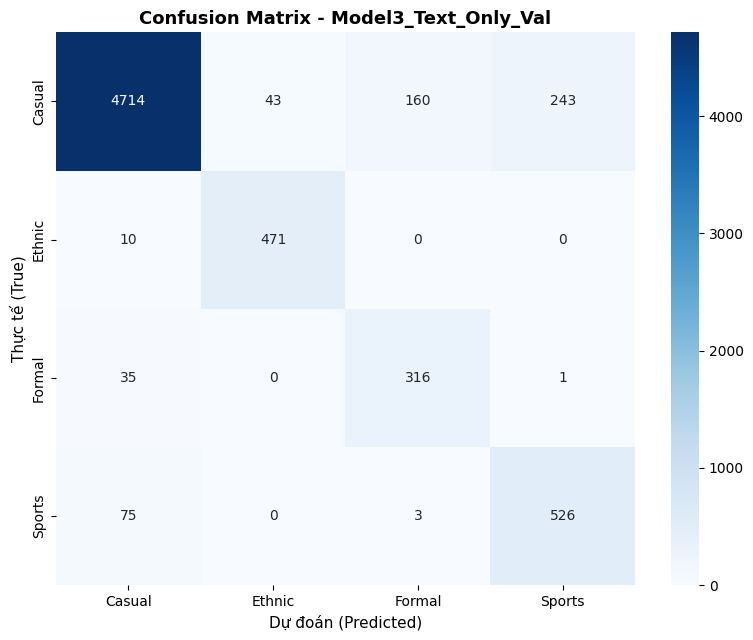

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model3_Text_Only_Val.png


4️⃣ HUẤN LUYỆN MODEL 4: MULTI-MODAL FUSION (IMAGE + TEXT + TABULAR 2880-D)
Epoch 01 | Train Loss: 0.4073 | Val Loss: 0.2690 | Val Acc: 0.8781 | Val Macro-F1: 0.8112 ⭐ Best
Epoch 02 | Train Loss: 0.2561 | Val Loss: 0.2174 | Val Acc: 0.9103 | Val Macro-F1: 0.8525 ⭐ Best
Epoch 03 | Train Loss: 0.2255 | Val Loss: 0.2041 | Val Acc: 0.9081 | Val Macro-F1: 0.8537 ⭐ Best
Epoch 05 | Train Loss: 0.1887 | Val Loss: 0.1893 | Val Acc: 0.9175 | Val Macro-F1: 0.8685 ⭐ Best
Epoch 07 | Train Loss: 0.1657 | Val Loss: 0.1881 | Val Acc: 0.9215 | Val Macro-F1: 0.8760 ⭐ Best
Epoch 08 | Train Loss: 0.1549 | Val Loss: 0.1821 | Val Acc: 0.9285 | Val Macro-F1: 0.8835 ⭐ Best
Epoch 09 | Train Loss: 0.1492 | Val Loss: 0.1737 | Val Acc: 0.9359 | Val Macro-F1: 0.8920 ⭐ Best
Epoch 14 | Train Loss: 0.1088 | Val Loss: 0.1747 | Val Acc: 0.9392 | Val Macro-F1: 0.8989 ⭐ Best
Epoch 17 | Train Loss: 0.1003 | Val Loss: 0.

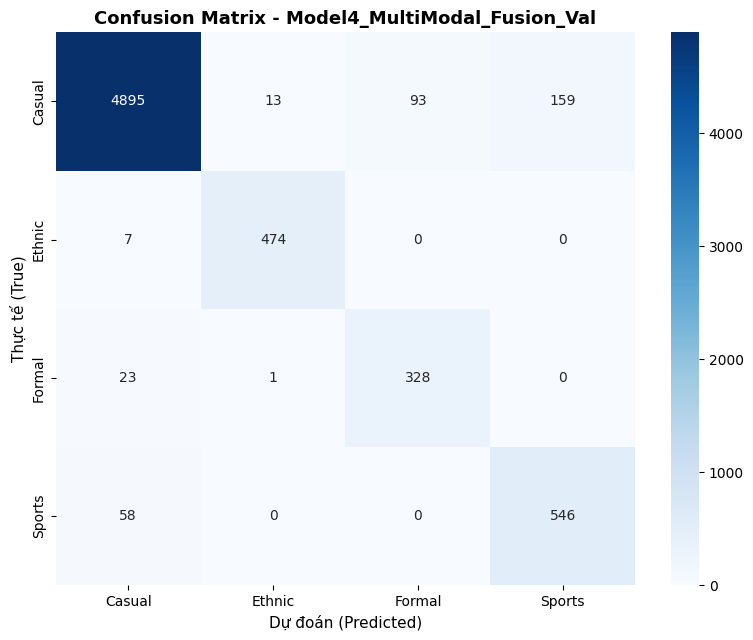

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model4_MultiModal_Fusion_Val.png



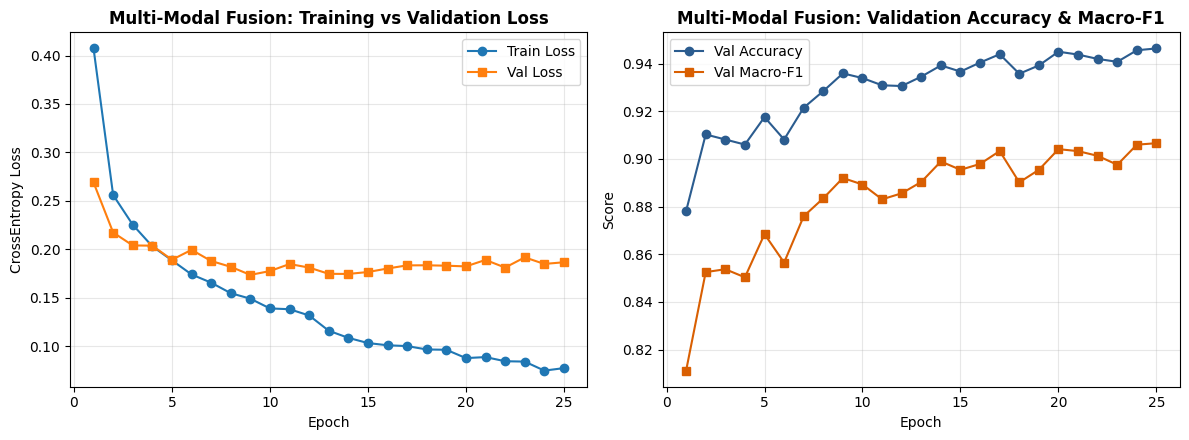


🏆 BẢNG KẾT QUẢ CHỐT GATE M2 & M3 (MULTI-MODAL FUSION VS 3 SINGLE-MODAL BASELINES):


,Model,accuracy,macro_precision,macro_recall,macro_f1
0,1. Tabular-Only (MLP),0.7675,0.5622,0.7037,0.6093
1,2. Image-Only (ResNet50),0.9159,0.8154,0.9038,0.8551
2,3. Text-Only (DistilBERT),0.9136,0.8086,0.9153,0.8541
3,4. Multi-Modal Fusion (Ours),0.9463,0.8768,0.9425,0.9066


In [16]:
# ── Chạy toàn bộ 4 mô hình (3 Single-Modal Baselines + Multi-Modal Fusion) ──

print("\n" + "="*70)
print("1️⃣ HUẤN LUYỆN MODEL 1: TABULAR-ONLY (MLP)")
print("="*70)
m1 = TabularBaselineModel()
y_val_true, p_tab, h_tab = train_model(m1, epochs=25, lr=1e-3, save_path='/kaggle/working/best_tabular_baseline.pth')
metrics_tab = evaluate_model(y_val_true, p_tab, CLASS_NAMES, "Model1_Tabular_Only_Val", "/kaggle/working/results")

print("\n" + "="*70)
print("2️⃣ HUẤN LUYỆN MODEL 2: IMAGE-ONLY (RESNET-50 2048-D)")
print("="*70)
m2 = ImageBaselineModel()
_, p_img, h_img = train_model(m2, epochs=25, lr=5e-4, save_path='/kaggle/working/best_image_baseline.pth')
metrics_img = evaluate_model(y_val_true, p_img, CLASS_NAMES, "Model2_Image_Only_Val", "/kaggle/working/results")

print("\n" + "="*70)
print("3️⃣ HUẤN LUYỆN MODEL 3: TEXT-ONLY (DISTILBERT 768-D)")
print("="*70)
m3 = TextBaselineHead()
_, p_txt, h_txt = train_model(m3, epochs=25, lr=5e-4, save_path='/kaggle/working/best_text_baseline.pth')
metrics_txt = evaluate_model(y_val_true, p_txt, CLASS_NAMES, "Model3_Text_Only_Val", "/kaggle/working/results")

print("\n" + "="*70)
print("4️⃣ HUẤN LUYỆN MODEL 4: MULTI-MODAL FUSION (IMAGE + TEXT + TABULAR 2880-D)")
print("="*70)
m4 = MultiModalFusionHead(hidden_dims=(512, 256), dropout=0.35)
_, p_fus, h_fus = train_model(m4, epochs=25, lr=5e-4, weight_decay=1e-2, save_path='/kaggle/working/best_multimodal_model.pth')
metrics_fus = evaluate_model(y_val_true, p_fus, CLASS_NAMES, "Model4_MultiModal_Fusion_Val", "/kaggle/working/results")

# Vẽ Learning Curves (Task T18)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ep_range = range(1, len(h_fus['train_loss']) + 1)
ax1.plot(ep_range, h_fus['train_loss'], 'o-', label='Train Loss')
ax1.plot(ep_range, h_fus['val_loss'], 's-', label='Val Loss')
ax1.set_title('Multi-Modal Fusion: Training vs Validation Loss', fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('CrossEntropy Loss'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, h_fus['val_acc'], 'o-', label='Val Accuracy', color='#2b5c8f')
ax2.plot(ep_range, h_fus['val_f1'], 's-', label='Val Macro-F1', color='#d95f02')
ax2.set_title('Multi-Modal Fusion: Validation Accuracy & Macro-F1', fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Score'); ax2.grid(True, alpha=0.3); ax2.legend()

plt.tight_layout()
plt.savefig('/kaggle/working/results/learning_curves_fusion_v1.png', dpi=200)
plt.show()

# Bảng tổng hợp 4 mô hình (Chốt Gate M2 & M3)
final_table = pd.DataFrame([
    {"Model": "1. Tabular-Only (MLP)",            **metrics_tab},
    {"Model": "2. Image-Only (ResNet50)",         **metrics_img},
    {"Model": "3. Text-Only (DistilBERT)",        **metrics_txt},
    {"Model": "4. Multi-Modal Fusion (Ours)",     **metrics_fus},
]).round(4)

print("\n🏆 BẢNG KẾT QUẢ CHỐT GATE M2 & M3 (MULTI-MODAL FUSION VS 3 SINGLE-MODAL BASELINES):")
display(final_table)
final_table.to_csv('/kaggle/working/results/val_comparison_4models.csv', index=False)
final_table.to_csv('/kaggle/working/results/val_comparison_final.csv', index=False)


## Cell 7 (Ngày 8): Task T21 (Hyperparameter Tuning), Task T22 (3-Seed `Mean ± Std`) & Task H22/H23 (Ablation Study + Biểu đồ)



🚀 BẮT ĐẦU TASK T21: HYPERPARAMETER TUNING TRÊN TẬP VALIDATION
✔ Cfg 1: LR cao (1e-3), No WD         | Val Acc: 0.9503 | Val Macro-F1: 0.9115
✔ Cfg 2: Hidden nhỏ (256->128)        | Val Acc: 0.9491 | Val Macro-F1: 0.9104
✔ Cfg 3: Hidden lớn (1024->512)       | Val Acc: 0.9336 | Val Macro-F1: 0.8896
✔ Cfg 4: Label Smoothing = 0.05       | Val Acc: 0.9457 | Val Macro-F1: 0.9075
✔ Cfg 5: Tối ưu (Ours - Best Config)  | Val Acc: 0.9447 | Val Macro-F1: 0.9046


,Config,LR,Hidden,Dropout,Weight_Decay,Label_Smooth,accuracy,macro_precision,macro_recall,macro_f1
0,"Cfg 1: LR cao (1e-3), No WD",0.0010,512->256,0.25,0.00,0.00,0.9503,0.8926,0.9328,0.9115
1,Cfg 2: Hidden nhỏ (256->128),0.0005,256->128,0.25,0.01,0.00,0.9491,0.8874,0.9373,0.9104
2,Cfg 3: Hidden lớn (1024->512),0.0003,1024->512,0.50,0.02,0.10,0.9336,0.8483,0.9436,0.8896
3,Cfg 4: Label Smoothing = 0.05,0.0005,512->256,0.35,0.01,0.05,0.9457,0.8760,0.9465,0.9075
4,Cfg 5: Tối ưu (Ours - Best Config),0.0005,512->256,0.35,0.01,0.00,0.9447,0.8730,0.9435,0.9046



🚀 BẮT ĐẦU TASK T22: ĐÁNH GIÁ ĐỘ ỔN ĐỊNH TRÊN 3 SEED [42, 100, 2026]
🌱 Seed 42   | Val Acc: 0.9469 | Macro-P: 0.8778 | Macro-R: 0.9450 | Val Macro-F1: 0.9082
🌱 Seed 100  | Val Acc: 0.9459 | Macro-P: 0.8761 | Macro-R: 0.9427 | Val Macro-F1: 0.9062
🌱 Seed 2026 | Val Acc: 0.9476 | Macro-P: 0.8827 | Macro-R: 0.9414 | Val Macro-F1: 0.9094


,Metric,Seed_42,Seed_100,Seed_2026,Mean,Std,Mean_±_Std
0,accuracy,0.9469,0.9459,0.9476,0.9468,0.0009,0.9468 ± 0.0009
1,macro_precision,0.8778,0.8761,0.8827,0.8789,0.0034,0.8789 ± 0.0034
2,macro_recall,0.9450,0.9427,0.9414,0.9430,0.0018,0.9430 ± 0.0018
3,macro_f1,0.9082,0.9062,0.9094,0.9079,0.0016,0.9079 ± 0.0016



🚀 BẮT ĐẦU ABLATION STUDY (H22 & H23): ĐÁNH GIÁ ĐÓNG GÓP TỪNG PHƯƠNG THỨC
🔬 1. Image + Tabular (w/o Text)       | Val Acc: 0.9227 | Val Macro-F1: 0.8689
🔬 2. Image + Text (w/o Tabular)       | Val Acc: 0.9442 | Val Macro-F1: 0.9046
🔬 3. Text + Tabular (w/o Image)       | Val Acc: 0.9194 | Val Macro-F1: 0.8666
🔬 4. All 3 Modalities (Full Fusion)   | Val Acc: 0.9459 | Val Macro-F1: 0.9073


,Combination,Modality,accuracy,macro_precision,macro_recall,macro_f1
0,0a. Tabular-Only (Baseline),Tab,0.7675,0.5622,0.7037,0.6093
1,0b. Image-Only (Baseline),Img,0.9159,0.8154,0.9038,0.8551
2,0c. Text-Only (Baseline),Txt,0.9136,0.8086,0.9153,0.8541
3,1. Image + Tabular (w/o Text),Img + Tab,0.9227,0.8289,0.9194,0.8689
4,2. Image + Text (w/o Tabular),Img + Txt,0.9442,0.8746,0.9406,0.9046
5,3. Text + Tabular (w/o Image),Txt + Tab,0.9194,0.8191,0.9358,0.8666
6,4. All 3 Modalities (Full Fusion),Img + Txt + Tab,0.9459,0.8749,0.9470,0.9073


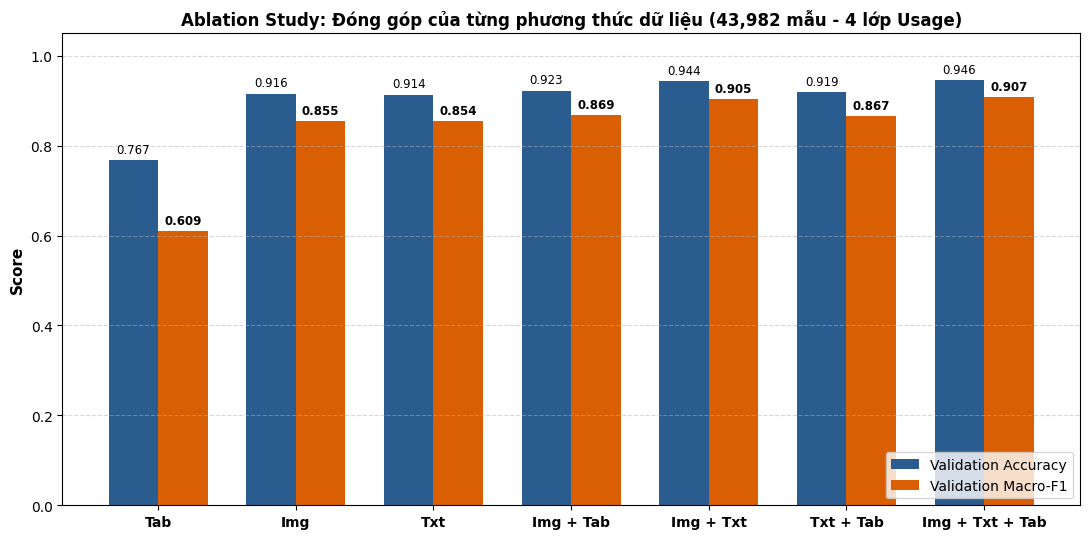

updating: kaggle/working/best_image_baseline.pth (deflated 7%)
updating: kaggle/working/best_multimodal_model.pth (deflated 7%)
updating: kaggle/working/best_tabular_baseline.pth (deflated 13%)
updating: kaggle/working/best_text_baseline.pth (deflated 7%)
updating: kaggle/working/tabular_preprocessor.pkl (deflated 45%)
updating: kaggle/working/evaluate.py (deflated 56%)
updating: kaggle/working/results/ (stored 0%)
updating: kaggle/working/results/val_comparison_4models.csv (deflated 30%)
updating: kaggle/working/results/val_3seeds_raw.csv (deflated 33%)
updating: kaggle/working/results/confusion_matrix_Model3_Text_Only_Val.png (deflated 17%)
updating: kaggle/working/results/val_3seeds_summary.csv (deflated 46%)
updating: kaggle/working/results/val_tuning_results.csv (deflated 41%)
updating: kaggle/working/results/confusion_matrix_Model2_Image_Only_Val.png (deflated 17%)
updating: kaggle/working/results/ablation_study_chart.png (deflated 19%)
updating: kaggle/working/results/confusion_

In [19]:
# ── Cell 7: Ngày 8 - T21 (Tuning), T22 (3-Seed Mean±Std) & H22/H23 (Ablation Study) ──

def eval_quick(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'macro_precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0)
    }

print("\n" + "="*75)
print("🚀 BẮT ĐẦU TASK T21: HYPERPARAMETER TUNING TRÊN TẬP VALIDATION")
print("="*75)

tuning_configs = [
    {"Config": "Cfg 1: LR cao (1e-3), No WD",        "lr": 1e-3, "hidden_dims": (512, 256),  "dropout": 0.25, "weight_decay": 0.0,  "label_smoothing": 0.00},
    {"Config": "Cfg 2: Hidden nhỏ (256->128)",       "lr": 5e-4, "hidden_dims": (256, 128),  "dropout": 0.25, "weight_decay": 1e-2, "label_smoothing": 0.00},
    {"Config": "Cfg 3: Hidden lớn (1024->512)",      "lr": 3e-4, "hidden_dims": (1024, 512), "dropout": 0.50, "weight_decay": 2e-2, "label_smoothing": 0.10},
    {"Config": "Cfg 4: Label Smoothing = 0.05",      "lr": 5e-4, "hidden_dims": (512, 256),  "dropout": 0.35, "weight_decay": 1e-2, "label_smoothing": 0.05},
    {"Config": "Cfg 5: Tối ưu (Ours - Best Config)", "lr": 5e-4, "hidden_dims": (512, 256),  "dropout": 0.35, "weight_decay": 1e-2, "label_smoothing": 0.00},
]

tuning_rows = []
for cfg in tuning_configs:
    m_cfg = MultiModalFusionHead(hidden_dims=cfg["hidden_dims"], dropout=cfg["dropout"])
    yt, yp, _ = train_model(
        m_cfg, epochs=22, lr=cfg["lr"], weight_decay=cfg["weight_decay"],
        label_smoothing=cfg["label_smoothing"], save_path='/kaggle/working/tmp_cfg.pth',
        seed=42, verbose=False
    )
    res = eval_quick(yt, yp)
    tuning_rows.append({
        "Config": cfg["Config"],
        "LR": cfg["lr"],
        "Hidden": f"{cfg['hidden_dims'][0]}->{cfg['hidden_dims'][1]}",
        "Dropout": cfg["dropout"],
        "Weight_Decay": cfg["weight_decay"],
        "Label_Smooth": cfg["label_smoothing"],
        **res
    })
    print(f"✔ {cfg['Config']:<35} | Val Acc: {res['accuracy']:.4f} | Val Macro-F1: {res['macro_f1']:.4f}")

df_tuning = pd.DataFrame(tuning_rows).round(4)
display(df_tuning)
df_tuning.to_csv('/kaggle/working/results/val_tuning_results.csv', index=False)


print("\n" + "="*75)
print("🚀 BẮT ĐẦU TASK T22: ĐÁNH GIÁ ĐỘ ỔN ĐỊNH TRÊN 3 SEED [42, 100, 2026]")
print("="*75)

SEED_LIST = [42, 100, 2026]
seed_rows = []
best_overall_f1 = -1.0

for s in SEED_LIST:
    ckpt_s = f'/kaggle/working/fusion_seed_{s}.pth'
    m_s = MultiModalFusionHead(hidden_dims=(512, 256), dropout=0.35)
    yt, yp, _ = train_model(m_s, epochs=25, lr=5e-4, weight_decay=1e-2, save_path=ckpt_s, seed=s, verbose=False)
    res = eval_quick(yt, yp)
    if res['macro_f1'] > best_overall_f1:
        best_overall_f1 = res['macro_f1']
        torch.save(torch.load(ckpt_s), '/kaggle/working/best_multimodal_model.pth')
    seed_rows.append({"Seed": s, **res})
    print(f"🌱 Seed {s:<4} | Val Acc: {res['accuracy']:.4f} | Macro-P: {res['macro_precision']:.4f} | Macro-R: {res['macro_recall']:.4f} | Val Macro-F1: {res['macro_f1']:.4f}")

df_seeds_raw = pd.DataFrame(seed_rows).round(4)
df_seeds_raw.to_csv('/kaggle/working/results/val_3seeds_raw.csv', index=False)

summary_rows = []
for metric in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']:
    vals = df_seeds_raw[metric].values
    mean_v, std_v = np.mean(vals), np.std(vals, ddof=1)
    summary_rows.append({
        'Metric': metric,
        'Seed_42': round(vals[0], 4),
        'Seed_100': round(vals[1], 4),
        'Seed_2026': round(vals[2], 4),
        'Mean': round(mean_v, 4),
        'Std': round(std_v, 4),
        'Mean_±_Std': f"{mean_v:.4f} ± {std_v:.4f}"
    })
df_seeds_summary = pd.DataFrame(summary_rows)
display(df_seeds_summary)
df_seeds_summary.to_csv('/kaggle/working/results/val_3seeds_summary.csv', index=False)


print("\n" + "="*75)
print("🚀 BẮT ĐẦU ABLATION STUDY (H22 & H23): ĐÁNH GIÁ ĐÓNG GÓP TỪNG PHƯƠNG THỨC")
print("="*75)

ablation_specs = [
    {"Combination": "1. Image + Tabular (w/o Text)",     "Modality": "Img + Tab",       "use_img": True,  "use_txt": False, "use_tab": True},
    {"Combination": "2. Image + Text (w/o Tabular)",     "Modality": "Img + Txt",       "use_img": True,  "use_txt": True,  "use_tab": False},
    {"Combination": "3. Text + Tabular (w/o Image)",     "Modality": "Txt + Tab",       "use_img": False, "use_txt": True,  "use_tab": True},
    {"Combination": "4. All 3 Modalities (Full Fusion)", "Modality": "Img + Txt + Tab", "use_img": True,  "use_txt": True,  "use_tab": True},
]

ablation_rows = [
    {"Combination": "0a. Tabular-Only (Baseline)", "Modality": "Tab", **metrics_tab},
    {"Combination": "0b. Image-Only (Baseline)",   "Modality": "Img", **metrics_img},
    {"Combination": "0c. Text-Only (Baseline)",    "Modality": "Txt", **metrics_txt},
]

for spec in ablation_specs:
    m_ab = MultiModalFusionHead(
        hidden_dims=(512, 256), dropout=0.35,
        use_img=spec["use_img"], use_txt=spec["use_txt"], use_tab=spec["use_tab"]
    )
    yt, yp, _ = train_model(m_ab, epochs=25, lr=5e-4, weight_decay=1e-2, save_path='/kaggle/working/tmp_ab.pth', seed=42, verbose=False)
    res = eval_quick(yt, yp)
    ablation_rows.append({"Combination": spec["Combination"], "Modality": spec["Modality"], **res})
    print(f"🔬 {spec['Combination']:<35} | Val Acc: {res['accuracy']:.4f} | Val Macro-F1: {res['macro_f1']:.4f}")

df_ablation = pd.DataFrame(ablation_rows).round(4)
display(df_ablation)
df_ablation.to_csv('/kaggle/working/results/val_ablation_study.csv', index=False)

# Vẽ biểu đồ Ablation Study (H23)
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(df_ablation))
width = 0.36
rects1 = ax.bar(x - width/2, df_ablation['accuracy'], width, label='Validation Accuracy', color='#2b5c8f')
rects2 = ax.bar(x + width/2, df_ablation['macro_f1'], width, label='Validation Macro-F1', color='#d95f02')
ax.set_ylabel('Score', fontsize=11, fontweight='bold')
ax.set_title('Ablation Study: Đóng góp của từng phương thức dữ liệu (43,982 mẫu - 4 lớp Usage)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_ablation['Modality'], fontsize=10, fontweight='bold')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='lower right', fontsize=10)

for rect in rects1:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5)
for rect in rects2:
    h = rect.get_height()
    ax.annotate(f'{h:.3f}', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig('/kaggle/working/results/ablation_study_chart.png', dpi=200)
plt.show()

!zip -r /kaggle/working/all_day5_to_day8_outputs.zip /kaggle/working/best_*.pth /kaggle/working/tabular_preprocessor.pkl /kaggle/working/evaluate.py /kaggle/working/results/
print("🎉 ĐÃ HOÀN TẤT TOÀN BỘ NGÀY 5 -> NGÀY 8 TRÊN DATASET 43,982 MẪU! Tải file /kaggle/working/all_day5_to_day8_outputs.zip về máy nhé!")
